# Positional Embeddings: From Sinusoids to RoPE

Attention compares every token with every other token, and it does so with
**no idea where any of them sit**. Shuffle the input and the outputs shuffle with
it, and nothing else changes. So every transformer has to inject position
somehow. The choice of how decides whether the model can read longer inputs
than it was trained on, and it is one of the few places where open-weight
architectures in 2026 still visibly differ.

This page follows the structure of Sebastian Raschka's
[*Understanding Positional Embeddings in Modern LLMs*](https://magazine.sebastianraschka.com/p/understanding-positional-embeddings)
(November 2026), which is the main reference here. Every number below is
computed in this notebook, and each claim is checked against a second way of
getting the same number.

1. Why attention needs position at all, shown by shuffling a sentence
2. Learned absolute positions (GPT-2)
3. Fixed sinusoids (the original Transformer), and the rotation hiding inside them
4. RoPE: rotate the query and key instead of adding anything
5. RoPE in many dimensions, and why distant tokens score lower
6. Split-half vs interleaved pairing: the same method, two memory layouts
7. Beyond full RoPE: partial RoPE, NoPE, ALiBi, and stretching the context

The full forward pass these vectors feed into is worked through in
[Autoregressive Transformer: Encoder + Decoder](/how-models-work/autoregressive-transformer-encoder-decoder/).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hmw_motion import Scene, diverge, mix

np.random.seed(7)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("-" * 78)


def check(label, a, b, tol=1e-9):
    ok = np.allclose(a, b, atol=tol)
    print(f"  [{'MATCH' if ok else 'DIFFERENT'}] {label}")
    return ok


def softmax(x, axis=-1):
    z = x - x.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


def self_attention(X, Wq, Wk, Wv):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    A = softmax(Q @ K.T / np.sqrt(K.shape[1]))
    return A @ V, A


print("helpers ready")

helpers ready


## 1. Attention cannot see order

Take three tokens, *dog bites man*, give each a random embedding, and run one
head of self-attention. Then run it again on *man bites dog*, which is the same
three vectors in a different order.

If attention knew about order, the two outputs would be unrelated. In fact the
second output is **exactly the first one with its rows swapped**. Every token
attends to the same set of tokens with the same weights, wherever they sit.
Formally, self-attention is *permutation-equivariant*: permuting the input rows
permutes the output rows the same way, and nothing more.

In [2]:
banner("SHUFFLE THE SENTENCE, SHUFFLE THE OUTPUT - NOTHING ELSE")

d = 6
vocab = {w: np.random.randn(d) for w in ["dog", "bites", "man"]}
Wq, Wk, Wv = (np.random.randn(d, d) * 0.5 for _ in range(3))

s1 = ["dog", "bites", "man"]
s2 = ["man", "bites", "dog"]
X1 = np.stack([vocab[w] for w in s1])
X2 = np.stack([vocab[w] for w in s2])

out1, A1 = self_attention(X1, Wq, Wk, Wv)
out2, A2 = self_attention(X2, Wq, Wk, Wv)

step("Output row for each word, in each sentence")
for w in ["dog", "bites", "man"]:
    print(f"  {w:>6}  in '{' '.join(s1)}': {out1[s1.index(w)]}")
    print(f"  {w:>6}  in '{' '.join(s2)}': {out2[s2.index(w)]}")

step("Checks")
perm = [s1.index(w) for w in s2]          # row i of s2 is row perm[i] of s1
check("output(man bites dog) == rows of output(dog bites man), reordered",
      out2, out1[perm])
check("mean-pooled sentence vectors are identical", out1.mean(0), out2.mean(0))
print()
print("  A classifier pooling these outputs could not tell who bit whom.")

  SHUFFLE THE SENTENCE, SHUFFLE THE OUTPUT - NOTHING ELSE

Output row for each word, in each sentence
------------------------------------------------------------------------------
     dog  in 'dog bites man': [-0.6234 -0.1298  0.1956  0.1003  0.1049 -0.4179]
     dog  in 'man bites dog': [-0.6234 -0.1298  0.1956  0.1003  0.1049 -0.4179]
   bites  in 'dog bites man': [-0.1309  0.0637  0.1204  0.1433 -0.0003 -0.4998]
   bites  in 'man bites dog': [-0.1309  0.0637  0.1204  0.1433 -0.0003 -0.4998]
     man  in 'dog bites man': [-0.8407  0.3119  0.1651 -0.0152 -0.5475 -0.2644]
     man  in 'man bites dog': [-0.8407  0.3119  0.1651 -0.0152 -0.5475 -0.2644]

Checks
------------------------------------------------------------------------------
  [MATCH] output(man bites dog) == rows of output(dog bites man), reordered
  [MATCH] mean-pooled sentence vectors are identical

  A classifier pooling these outputs could not tell who bit whom.


## 2. Learned absolute positions (GPT-2)

The simplest fix is to give every *slot* its own trainable vector and add it to
the token embedding before the first layer:

$$h_m = E[x_m] + P[m]$$

$E$ is the token embedding table and $P$ is a second table with one row per
position. GPT-2 trains $P$ along with everything else, with 1,024 rows.

Once the position rows are added, the shuffle test fails, which is what we want:
*dog* in slot 0 and *dog* in slot 2 are now different vectors.

The cost is that the table **ends at 1,024**. Position 1,025 has no row. You
cannot ask the model to read a longer input without adding rows that were never
trained, so the context length is fixed when the model is built.

In [3]:
banner("LEARNED POSITION TABLE")

P_learned = np.random.randn(3, d) * 0.8          # stands in for a trained table
o1, _ = self_attention(X1 + P_learned, Wq, Wk, Wv)
o2, _ = self_attention(X2 + P_learned, Wq, Wk, Wv)

step("Same shuffle test, after adding position rows")
check("output(man bites dog) == reordered output(dog bites man)", o2, o1[perm])
print(f"  largest difference between the two pooled vectors: "
      f"{np.abs(o1.mean(0) - o2.mean(0)).max():.4f}")

step("Size of the position table in the GPT-2 family (1,024 positions)")
for name, dm in [("GPT-2 small", 768), ("GPT-2 medium", 1024),
                 ("GPT-2 large", 1280), ("GPT-2 XL", 1600)]:
    print(f"  {name:<13} d_model={dm:>5}   1024 x {dm:<5} = {1024*dm:>9,} parameters")
print()
print("  Every one of those rows is learned from data. Row 1,024 does not exist.")

  LEARNED POSITION TABLE

Same shuffle test, after adding position rows
------------------------------------------------------------------------------
  [DIFFERENT] output(man bites dog) == reordered output(dog bites man)
  largest difference between the two pooled vectors: 0.4822

Size of the position table in the GPT-2 family (1,024 positions)
------------------------------------------------------------------------------
  GPT-2 small   d_model=  768   1024 x 768   =   786,432 parameters
  GPT-2 medium  d_model= 1024   1024 x 1024  = 1,048,576 parameters
  GPT-2 large   d_model= 1280   1024 x 1280  = 1,310,720 parameters
  GPT-2 XL      d_model= 1600   1024 x 1600  = 1,638,400 parameters

  Every one of those rows is learned from data. Row 1,024 does not exist.


## 3. Fixed sinusoids, and the rotation hidden inside them

The original Transformer (Vaswani et al., 2017) uses a fixed table instead of a
learned one. Feature pairs $(2i, 2i{+}1)$ get a sine and a cosine at frequency
$\omega_i$:

$$P_{m,2i} = \sin(m\,\omega_i), \qquad P_{m,2i+1} = \cos(m\,\omega_i), \qquad
\omega_i = 10000^{-2i/d}$$

The first pair turns fast and the last pair turns very slowly. Read the whole
vector at once and it works like an odometer: a fast digit, then slower and
slower ones, so every position up to a very large one gets a distinct pattern.

The property that matters most is not obvious from the formula. Each
(sin, cos) pair is a point on a unit circle, and moving $k$ positions forward
**rotates that point by the angle** $k\,\omega_i$:

$$\begin{pmatrix}\sin((m{+}k)\omega)\\ \cos((m{+}k)\omega)\end{pmatrix}
= \begin{pmatrix}\cos k\omega & \sin k\omega\\ -\sin k\omega & \cos k\omega\end{pmatrix}
\begin{pmatrix}\sin m\omega\\ \cos m\omega\end{pmatrix}$$

That matrix depends only on the offset $k$, not on $m$. So "three tokens later"
is the same linear map everywhere in the sequence. RoPE builds directly on this.

  SINUSOIDAL TABLE

Frequencies for d = 64 (radians per position), first and last few
------------------------------------------------------------------------------
   [1.     0.7499 0.5623 0.4217] ... [0.0002 0.0002 0.0001]
  wavelength of the fastest pair: 6.28 positions
  wavelength of the slowest pair: 47,117 positions

Moving k positions forward is a rotation that depends only on k
------------------------------------------------------------------------------
  27 (k, m, pair) combinations, worst error: 9.44e-16
  [MATCH] P[m+k] pair == R(k*w) @ P[m] pair, for every combination


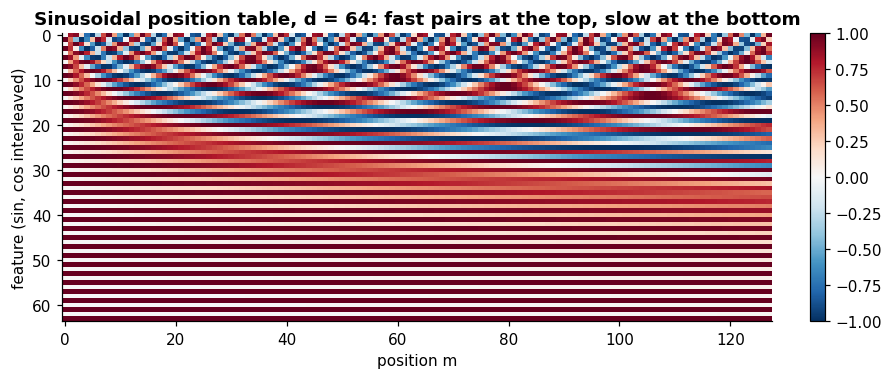

In [4]:
banner("SINUSOIDAL TABLE")

def sinusoidal(L, d, base=10000.0):
    m = np.arange(L)[:, None]
    i = np.arange(d // 2)[None, :]
    w = base ** (-2 * i / d)
    P = np.zeros((L, d))
    P[:, 0::2] = np.sin(m * w)
    P[:, 1::2] = np.cos(m * w)
    return P, w.ravel()

P, w = sinusoidal(128, 64)
step("Frequencies for d = 64 (radians per position), first and last few")
print("  ", np.round(w[:4], 5), "...", np.round(w[-3:], 6))
print(f"  wavelength of the fastest pair: {2*np.pi/w[0]:.2f} positions")
print(f"  wavelength of the slowest pair: {2*np.pi/w[-1]:,.0f} positions")

step("Moving k positions forward is a rotation that depends only on k")
worst = 0.0
for k in [1, 5, 17]:
    for m in [0, 9, 60]:
        for i in [0, 7, 31]:
            a = k * w[i]
            R = np.array([[np.cos(a), np.sin(a)], [-np.sin(a), np.cos(a)]])
            worst = max(worst, np.abs(R @ P[m, 2*i:2*i+2] - P[m+k, 2*i:2*i+2]).max())
print(f"  27 (k, m, pair) combinations, worst error: {worst:.2e}")
check("P[m+k] pair == R(k*w) @ P[m] pair, for every combination", worst, 0.0)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(P.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xlabel("position m")
ax.set_ylabel("feature (sin, cos interleaved)")
ax.set_title("Sinusoidal position table, d = 64: fast pairs at the top, slow at the bottom")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025)

Watch the odometer turn. Each dial is one (sin, cos) pair of an 8-dimensional
table, and the hand's angle is $m\,\omega_i$. The first hand spins a full turn
roughly every six positions. The last one has barely moved after fifty.

In [5]:
d8 = 8
w8 = 10000.0 ** (-2 * np.arange(d8 // 2) / d8)
M = 48
s = Scene(720, 370, dur=0.8 + M * 0.17 + 0.4,
          caption="Sinusoidal encoding, d = 8: four dials turning at four frequencies",
          poster=0.8 + 30 * 0.17)
s.text(360, 26, "position m =", size=16, fill="muted", anchor="end")
mnum = s.num(368, 26, 0, dec=0, size=18, fill="amber", anchor="start")
xs = [110, 270, 430, 590]
hands, sins, coss = [], [], []
for i, cx in enumerate(xs):
    s.circle(cx, 150, r=62, fill="panel", stroke="grid", sw=2)
    s.line(cx - 62, 150, cx + 62, 150, stroke="grid", sw=1)
    s.line(cx, 88, cx, 212, stroke="grid", sw=1)
    s.text(cx, 72, f"pair {i}   ω = {w8[i]:g}", size=12, fill="muted")
    hands.append(s.polar(cx, 150, 56, 90, stroke=["cyan", "violet", "pink", "amber"][i], sw=3))
    s.text(cx - 26, 236, "sin", size=11, fill="muted")
    s.text(cx + 30, 236, "cos", size=11, fill="muted")
    sins.append(s.num(cx - 26, 254, 0.0, dec=2, size=13))
    coss.append(s.num(cx + 30, 254, 1.0, dec=2, size=13))
# the 8-number vector P_m as a strip of cells
s.text(360, 292, "P[m]  (8 numbers, coloured by sign and size)", size=12, fill="muted")
cells = []
for j in range(d8):
    cells.append(s.rect(200 + j * 40, 306, 36, 36, fill=diverge(P[0, j] if j < 64 else 0), rx=5))
P8, _ = sinusoidal(M + 1, d8)
for j in range(d8):
    cells[j].set(0, fill=diverge(P8[0, j]))
for m in range(1, M + 1):
    t0, t1 = 0.8 + (m - 1) * 0.17, 0.8 + m * 0.17
    mnum.to(t0, t1, v=m, ease="lin")
    for i in range(4):
        # angle measured from 12 o'clock so position 0 points up; unwrapped so it never jumps
        hands[i].to(t0, t1, ang=90 - np.degrees(m * w8[i]), ease="lin")
        sins[i].to(t0, t1, v=np.sin(m * w8[i]), ease="lin")
        coss[i].to(t0, t1, v=np.cos(m * w8[i]), ease="lin")
    for j in range(d8):
        cells[j].to(t0, t1, fill=diverge(P8[m, j]), ease="lin")
s.beat(0.0, "Every position gets one angle per pair: m times that pair's frequency.")
s.beat(0.8 + 8 * 0.17, "Pair 0 turns 1 radian per position, so it wraps around about every 6 positions.")
s.beat(0.8 + 24 * 0.17, "Pair 3 turns 1,000 times slower. Together the dials never repeat a reading.")
s

<motion scene: Sinusoidal encoding, d = 8: four dials turning at four frequencies (47 elements, 9.36s)>

## 4. RoPE: rotate the query and the key

Adding a position vector mixes *where* into *what* before attention ever runs,
and the model has to learn to untangle them. **Rotary Position Embedding**
(Su et al., 2021, the RoFormer paper) takes the rotation property above and
applies it where it matters, inside the attention score.

Split the query and key into pairs. Rotate the pair of a query at position $m$
by $m\theta$, and the pair of a key at position $n$ by $n\theta$:

$$q'_m = R(m\theta)\,q, \qquad k'_n = R(n\theta)\,k, \qquad
R(\alpha) = \begin{pmatrix}\cos\alpha & -\sin\alpha\\ \sin\alpha & \cos\alpha\end{pmatrix}$$

Rotations preserve length and compose by adding angles. So the score is

$$q'^{\top}_m k'_n = q^\top R(m\theta)^\top R(n\theta)\,k = q^\top R\big((n-m)\theta\big)\,k$$

**Only the offset $n-m$ survives.** Absolute positions cancel out of the
attention score exactly. Nothing is added to the token embedding, the values
are not rotated, and there are no extra parameters.

A worked 2-D example. The angle per position is $\theta = 30°$, the query is
at position 4 and the key at position 1.

In [6]:
banner("RoPE BY HAND IN TWO DIMENSIONS")

def R(a):
    return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])

theta = np.radians(30)
q = np.array([0.9, 0.4])
k = np.array([0.5, 1.1])
m, n = 4, 1

step(f"Rotate the query by m*theta = {m}*30 = {m*30} degrees")
c, s_ = np.cos(m * theta), np.sin(m * theta)
qr = np.array([q[0]*c - q[1]*s_, q[0]*s_ + q[1]*c])
print(f"  q0' = {q[0]}*cos({m*30}) - {q[1]}*sin({m*30}) = {q[0]}*({c:+.4f}) - {q[1]}*({s_:+.4f}) = {qr[0]:+.4f}")
print(f"  q1' = {q[0]}*sin({m*30}) + {q[1]}*cos({m*30}) = {q[0]}*({s_:+.4f}) + {q[1]}*({c:+.4f}) = {qr[1]:+.4f}")
check("by-hand rotation == R(m*theta) @ q", qr, R(m * theta) @ q)

step(f"Rotate the key by n*theta = {n}*30 = {n*30} degrees")
kr = R(n * theta) @ k
print(f"  k' = {kr}")

step("Lengths do not change")
print(f"  |q| = {np.linalg.norm(q):.4f}   |q'| = {np.linalg.norm(qr):.4f}")
print(f"  |k| = {np.linalg.norm(k):.4f}   |k'| = {np.linalg.norm(kr):.4f}")

step("The score, three ways")
score = qr @ kr
print(f"  q'.k'                                = {score:+.6f}")
print(f"  q . R((n-m)*theta) k   (offset only) = {q @ R((n - m) * theta) @ k:+.6f}")
qs, ks = R((m + 10) * theta) @ q, R((n + 10) * theta) @ k
print(f"  both shifted by 10 positions          = {qs @ ks:+.6f}")
check("score depends only on n - m", [score, qs @ ks], [q @ R((n - m) * theta) @ k] * 2)

step("Compare: the same two vectors two positions apart instead of three")
print(f"  (m, n) = (4, 2): {(R(4*theta) @ q) @ (R(2*theta) @ k):+.6f}")
print(f"  (m, n) = (9, 7): {(R(9*theta) @ q) @ (R(7*theta) @ k):+.6f}")

  RoPE BY HAND IN TWO DIMENSIONS

Rotate the query by m*theta = 4*30 = 120 degrees
------------------------------------------------------------------------------
  q0' = 0.9*cos(120) - 0.4*sin(120) = 0.9*(-0.5000) - 0.4*(+0.8660) = -0.7964
  q1' = 0.9*sin(120) + 0.4*cos(120) = 0.9*(+0.8660) + 0.4*(-0.5000) = +0.5794
  [MATCH] by-hand rotation == R(m*theta) @ q

Rotate the key by n*theta = 1*30 = 30 degrees
------------------------------------------------------------------------------
  k' = [-0.117   1.2026]

Lengths do not change
------------------------------------------------------------------------------
  |q| = 0.9849   |q'| = 0.9849
  |k| = 1.2083   |k'| = 1.2083

The score, three ways
------------------------------------------------------------------------------
  q'.k'                                = +0.790000
  q . R((n-m)*theta) k   (offset only) = +0.790000
  both shifted by 10 positions          = +0.790000
  [MATCH] score depends only on n - m

Compare: the same two vecto

Here is that algebra in motion. The query (cyan) and key (pink) both step
forward one position at a time and both turn by 30° per step. The **angle
between them does not change**, so neither does their dot product. Then the key
moves by itself, the offset changes, and the score changes with it.

In [7]:
def rope_scene():
    cx, cy, L = 230, 196, 150
    sc = Scene(720, 390, dur=12.5, caption="RoPE in 2-D: the score depends only on the offset",
               poster=5.2)
    sc.circle(cx, cy, r=L, fill="panel", stroke="grid", sw=1.5)
    sc.line(cx - L - 10, cy, cx + L + 10, cy, stroke="grid", sw=1)
    sc.line(cx, cy - L - 10, cx, cy + L + 10, stroke="grid", sw=1)
    phq, phk = np.degrees(np.arctan2(q[1], q[0])), np.degrees(np.arctan2(k[1], k[0]))
    scale = 0.95 * L / max(np.linalg.norm(q), np.linalg.norm(k))

    def angs(mm, nn):
        return phq + mm * 30, phk + nn * 30

    seq = [(4, 1), (5, 2), (6, 3), (7, 4), (7, 5), (7, 6), (8, 7)]
    aq, ak = angs(*seq[0])
    arc = sc.arc(cx, cy, 46, ak, aq, stroke="amber", sw=3)
    qa = sc.polar(cx, cy, np.linalg.norm(q) * scale, aq, stroke="cyan", sw=4, head=13)
    ka = sc.polar(cx, cy, np.linalg.norm(k) * scale, ak, stroke="pink", sw=4, head=13)

    X = 440
    sc.text(X, 60, "query position m", size=14, fill="cyan", anchor="start")
    sc.text(X, 100, "key position n", size=14, fill="pink", anchor="start")
    sc.text(X, 140, "offset n - m", size=14, fill="amber", anchor="start")
    sc.text(X, 196, "score q'.k'", size=15, fill="text", anchor="start", weight=700)
    nm = sc.num(680, 60, seq[0][0], dec=0, size=18, fill="cyan", anchor="end")
    nn = sc.num(680, 100, seq[0][1], dec=0, size=18, fill="pink", anchor="end")
    no = sc.num(680, 140, seq[0][1] - seq[0][0], dec=0, size=18, fill="amber", anchor="end")
    ns = sc.num(680, 196, (R(4*theta) @ q) @ (R(1*theta) @ k), dec=4, size=22,
                fill="text", anchor="end")
    sc.line(X, 168, 690, 168, stroke="grid", sw=1)
    hist = sc.text(X, 250, "", size=13, fill="muted", anchor="start", mono=True)
    hist2 = sc.text(X, 274, "", size=13, fill="muted", anchor="start", mono=True)
    hist3 = sc.text(X, 298, "", size=13, fill="muted", anchor="start", mono=True)

    t = 1.2
    lines = []
    for (m0, n0), (m1, n1) in zip(seq[:-1], seq[1:]):
        aq, ak = angs(m1, n1)
        sc_val = (R(m1*theta) @ q) @ (R(n1*theta) @ k)
        qa.to(t, t + 0.9, ang=aq)
        ka.to(t, t + 0.9, ang=ak)
        arc.to(t, t + 0.9, a0=ak, a1=aq)
        nm.to(t, t + 0.5, v=m1, ease="lin")
        nn.to(t, t + 0.5, v=n1, ease="lin")
        no.to(t, t + 0.5, v=n1 - m1, ease="lin")
        ns.to(t, t + 0.9, v=sc_val)
        lines.append(f"({m1},{n1})  offset {n1-m1:+d}  score {sc_val:+.4f}")
        for el, txt in zip([hist, hist2, hist3], lines[-3:]):
            el.set(t + 0.9, s=txt)
        t += 1.6
    sc.beat(0.0, "Query at 4, key at 1: both vectors are rotated by their own position.")
    sc.beat(1.2, "Shift both forward together. Both rotate by the same 30 degrees...")
    sc.beat(3.6, "...so the amber angle between them never changes, and the score stays fixed.")
    sc.beat(6.0, "Now move only the key. The offset changes, so the angle and the score change.")
    sc.beat(10.8, "One offset, one score: attention sees relative position.")
    return sc

rope_scene()

<motion scene: RoPE in 2-D: the score depends only on the offset (18 elements, 12.5s)>

## 5. RoPE in many dimensions, and why far-away tokens score lower

A real head has $d$ features, so it has $d/2$ pairs. Each pair rotates at its
own rate, chosen exactly like the sinusoidal frequencies:

$$\theta_i = b^{-2i/d}, \qquad b = 10{,}000\ \text{(the usual base)}$$

Fast pairs tell neighbouring tokens apart. Slow pairs still distinguish tokens
thousands of positions away. The relative-position property holds pair by pair,
so it holds for the whole vector. The next cell checks it on random vectors with
$d = 128$.

The RoFormer paper also points out a useful side effect. When the frequencies
are spread like this, the score between two fixed vectors tends to **decay as
the distance grows**. At offset 0 every pair contributes positively. Further
apart, the pairs point in increasingly unrelated directions and partly cancel.
The plot uses $q = k$ = all ones, which is the case the paper's bound is about.

  RoPE WITH d = 128

Score for offset n - m = 5, at many absolute positions
------------------------------------------------------------------------------
  m =      0, n =      5:  score = -6.7021265386
  m =      1, n =      6:  score = -6.7021265386
  m =     37, n =     42:  score = -6.7021265386
  m =    500, n =    505:  score = -6.7021265386
  m =   4000, n =   4005:  score = -6.7021265386
  m = 100000, n = 100005:  score = -6.7021265386
  spread across positions: 1.77e-12
  [MATCH] RoPE score depends only on the offset (d = 128)
  [MATCH] rotation preserves the norm

All-ones q and k: score at selected offsets
------------------------------------------------------------------------------
  offset     0: +128.000
  offset     1: +124.187
  offset     4:  +97.172
  offset    16:  +79.403
  offset    64:  +61.040
  offset   256:  +41.050
  offset  1024:  +26.169
  offset  2048:  +15.268


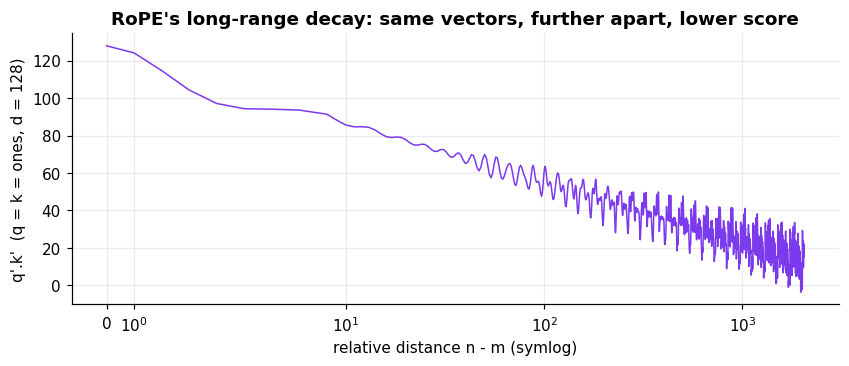

In [8]:
banner("RoPE WITH d = 128")

def rope(x, pos, base=10000.0):
    """Split-half RoPE (feature i paired with i + d/2). x: (..., d)."""
    dd = x.shape[-1]
    half = dd // 2
    th = base ** (-2 * np.arange(half) / dd)
    ang = np.asarray(pos)[..., None] * th
    c, s_ = np.cos(ang), np.sin(ang)
    x1, x2 = x[..., :half], x[..., half:]
    return np.concatenate([x1 * c - x2 * s_, x1 * s_ + x2 * c], axis=-1)

dh = 128
qv, kv = np.random.randn(dh), np.random.randn(dh)

step("Score for offset n - m = 5, at many absolute positions")
scores = [rope(qv, mm) @ rope(kv, mm + 5) for mm in [0, 1, 37, 500, 4000, 100000]]
for mm, sv in zip([0, 1, 37, 500, 4000, 100000], scores):
    print(f"  m = {mm:>6}, n = {mm+5:>6}:  score = {sv:+.10f}")
print(f"  spread across positions: {np.ptp(scores):.2e}")
check("RoPE score depends only on the offset (d = 128)", scores, [scores[0]] * len(scores), tol=1e-8)
check("rotation preserves the norm", np.linalg.norm(rope(qv, 4000)), np.linalg.norm(qv))

ones = np.ones(dh)
offs = np.arange(0, 2049)
decay = np.array([rope(ones, 0) @ rope(ones, o) for o in offs])
step("All-ones q and k: score at selected offsets")
for o in [0, 1, 4, 16, 64, 256, 1024, 2048]:
    print(f"  offset {o:>5}: {decay[o]:+8.3f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(offs, decay, lw=1, color="#7c3aed")
ax.set_xscale("symlog", linthresh=8)
ax.set_xlabel("relative distance n - m (symlog)")
ax.set_ylabel("q'.k'  (q = k = ones, d = 128)")
ax.set_title("RoPE's long-range decay: same vectors, further apart, lower score")

## 6. Split-half vs interleaved: one method, two layouts

Which features count as "a pair" is a convention.

* **Interleaved**: pairs are $(0,1), (2,3), (4,5), \dots$, as in the RoFormer
  paper and in Meta's original Llama code, which treats each pair as a complex
  number.
* **Split-half**: feature $i$ is paired with $i + d/2$, as in the Hugging Face
  `rotate_half` implementation, which is what the code above does.

They are the same transformation applied to permuted features. A model trained
with one layout works with the other only if its query and key weight rows are
permuted to match, which is exactly what checkpoint conversion scripts do. Get
it wrong and nothing crashes; the model just quietly produces worse text.

In [9]:
banner("INTERLEAVED == SPLIT-HALF, UP TO A FEATURE PERMUTATION")

def rope_interleaved(x, pos, base=10000.0):
    dd = x.shape[-1]
    th = base ** (-2 * np.arange(dd // 2) / dd)
    ang = pos * th
    c, s_ = np.cos(ang), np.sin(ang)
    out = x.copy()
    out[0::2] = x[0::2] * c - x[1::2] * s_
    out[1::2] = x[0::2] * s_ + x[1::2] * c
    return out

d8 = 8
print("  interleaved pairs:", [(2*i, 2*i+1) for i in range(d8 // 2)])
print("  split-half pairs: ", [(i, i + d8 // 2) for i in range(d8 // 2)])
perm_ = np.concatenate([np.arange(0, dh, 2), np.arange(1, dh, 2)])   # interleaved -> split
x = np.random.randn(dh)
a = rope_interleaved(x, 321)[perm_]
b = rope(x[perm_], 321)
check("rope_interleaved(x)[perm] == rope_split(x[perm])", a, b)
mix_ = rope(qv, 10) @ rope_interleaved(kv, 15)
same = rope(qv, 10) @ rope(kv, 15)
print(f"  consistent layout score:  {same:+.6f}")
print(f"  mismatched layout score:  {mix_:+.6f}   <- silently wrong")

  INTERLEAVED == SPLIT-HALF, UP TO A FEATURE PERMUTATION
  interleaved pairs: [(0, 1), (2, 3), (4, 5), (6, 7)]
  split-half pairs:  [(0, 4), (1, 5), (2, 6), (3, 7)]
  [MATCH] rope_interleaved(x)[perm] == rope_split(x[perm])
  consistent layout score:  -6.702127
  mismatched layout score:  +1.159566   <- silently wrong


## 7. Beyond full RoPE

Full RoPE on every feature of every layer is still the most common choice
among 2026 open-weight models, according to Raschka's survey. It is no longer
the only one.

| Method | What it does | Seen in |
|---|---|---|
| Learned absolute | add a trained vector per slot | GPT-2 |
| Sinusoidal | add a fixed sin/cos vector per slot | original Transformer |
| RoPE | rotate $q$, $k$ by position, nothing added | Llama, Qwen, most 2026 models |
| Partial RoPE | rotate only some of each head's features, leave the rest position-free | e.g. MiniMax-M3 (64 of 128 dims) |
| NoPE | no positional signal; the causal mask alone implies order | some layers of SmolLM3 |
| Relative bias | learned scalar per distance bucket, added to scores | T5 |
| ALiBi | fixed penalty $-s_h\,(n-m)$ added to scores | BLOOM, MPT |

**NoPE works at all** because a causal mask is not symmetric: token 5 can see
five earlier tokens and token 1 can see one, so the model can count. It is
usually mixed with RoPE layers rather than used everywhere.

**ALiBi** skips vectors entirely. Head $h$ subtracts a linear penalty
proportional to distance, with slopes $s_h = 2^{-8h/H}$, so some heads look
locally and others far away.

  ALiBi SLOPES AND BIAS
  slopes for 8 heads: [0.5    0.25   0.125  0.0625 0.0312 0.0156 0.0078 0.0039]
  as fractions: 1/2, 1/4, 1/8, 1/16, 1/32, 1/64, 1/128, 1/256


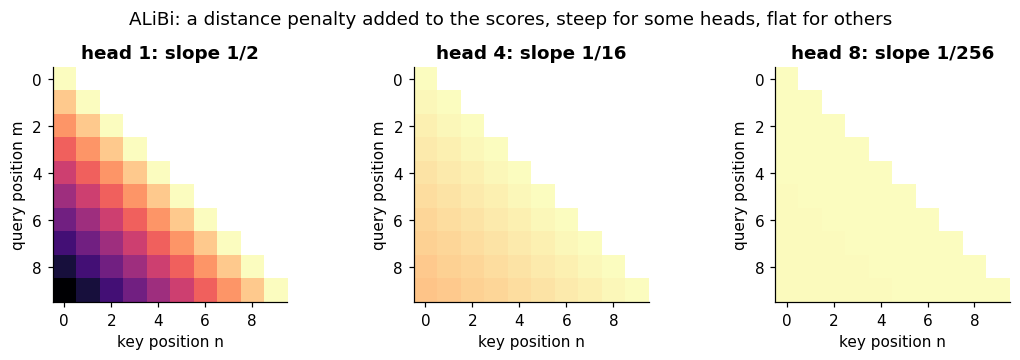

In [10]:
banner("ALiBi SLOPES AND BIAS")

H = 8
slopes = 2.0 ** (-8 * np.arange(1, H + 1) / H)
print("  slopes for 8 heads:", np.round(slopes, 5))
print("  as fractions: 1/" + ", 1/".join(f"{1/sv:g}" for sv in slopes))
T_ = 10
dist = np.arange(T_)[None, :] - np.arange(T_)[:, None]           # n - m
causal = dist <= 0
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, h in zip(axes, [0, 3, 7]):
    B = np.where(causal, slopes[h] * dist, np.nan)
    im = ax.imshow(B, cmap="magma", vmin=-slopes[0] * (T_ - 1), vmax=0)
    ax.set_title(f"head {h+1}: slope 1/{1/slopes[h]:g}")
    ax.set_xlabel("key position n"); ax.set_ylabel("query position m")
    ax.grid(False)
fig.suptitle("ALiBi: a distance penalty added to the scores, steep for some heads, flat for others")
fig.tight_layout()

### Stretching the context: extrapolate or interpolate?

A RoPE model trained on 2,048 tokens has seen every angle that its fast pairs can
take, because those wrap around many times. Its **slow pairs never wrap**. For
pair $i = 50$ of a 128-dim head, the largest angle seen in training is about
90°. Run the same model at 8,192 tokens and that pair reaches angles it has
never seen, all the way around the dial.

**Position interpolation** (Chen et al., 2023) divides every position by
$L'/L$, here 4, so the longest new input maps back into the trained range. The
cost is that neighbouring tokens are now four times closer in angle, so a short
fine-tune is needed. Later methods such as NTK-aware scaling and YaRN scale the
fast and slow pairs differently, to keep the fast pairs sharp.

In [11]:
banner("WHICH ANGLES DOES A SLOW PAIR SEE?")
Ltrain, Lnew, dh, i50 = 2048, 8192, 128, 50
th50 = 10000.0 ** (-2 * i50 / dh)
print(f"  theta_50 = 10000^(-100/128) = {th50:.3e} rad per position")
print(f"  largest angle in training  (m = {Ltrain}):  {np.degrees(Ltrain*th50):7.1f} degrees")
print(f"  extrapolated to m = {Lnew}:               {np.degrees(Lnew*th50):7.1f} degrees  <- unseen")
print(f"  interpolated, m * {Ltrain}/{Lnew}:              {np.degrees(Lnew*th50*Ltrain/Lnew):7.1f} degrees  <- in range")
th0 = 1.0
print(f"  fastest pair wraps {Ltrain*th0/(2*np.pi):.0f} times during training: every angle already seen")

sc = Scene(720, 360, dur=9.5, caption="Pair 50 of a 128-dim head, trained on 2,048 tokens, run on 8,192",
           poster=7.5)
for cx, title, col in [(190, "extrapolate", "red"), (530, "position interpolation", "green")]:
    sc.circle(cx, 180, r=110, fill="panel", stroke="grid", sw=2)
    sc.arc(cx, 180, 110, 90, 90 - np.degrees(Ltrain * th50), stroke="green", sw=10)
    sc.text(cx, 40, title, size=16, fill=col, weight=700)
sc.text(360, 318, "green band = angles seen in training", size=12, fill="green")
hl = sc.polar(190, 180, 100, 90, stroke="cyan", sw=4, head=12)
hr = sc.polar(530, 180, 100, 90, stroke="cyan", sw=4, head=12)
pos = sc.num(360, 345, 0, dec=0, pre="position m = ", size=14, fill="amber")
for j in range(1, 41):
    mm = Lnew * j / 40
    t0, t1 = 0.6 + (j - 1) * 0.2, 0.6 + j * 0.2
    hl.to(t0, t1, ang=90 - np.degrees(mm * th50), ease="lin")
    hr.to(t0, t1, ang=90 - np.degrees(mm * th50 * Ltrain / Lnew), ease="lin")
    pos.to(t0, t1, v=mm, ease="lin")
    if mm > Ltrain and j == 11:
        hl.to(t1, t1 + 0.01, stroke="red")
sc.beat(0.0, "Position runs from 0 to 8,192. Each hand shows this pair's angle at that position.")
sc.beat(0.6 + 10 * 0.2, "Past position 2,048 the left hand leaves the trained band: unseen angles.")
sc.beat(5.2, "Interpolation divides positions by 4, so the right hand never leaves the band.")
sc

  WHICH ANGLES DOES A SLOW PAIR SEE?
  theta_50 = 10000^(-100/128) = 7.499e-04 rad per position
  largest angle in training  (m = 2048):     88.0 degrees
  extrapolated to m = 8192:                 352.0 degrees  <- unseen
  interpolated, m * 2048/8192:                 88.0 degrees  <- in range
  fastest pair wraps 326 times during training: every angle already seen


<motion scene: Pair 50 of a 128-dim head, trained on 2,048 tokens, run on 8,192 (10 elements, 9.5s)>

## Summary

* Self-attention is permutation-equivariant. Without a position signal it
  computes the same thing for *dog bites man* and *man bites dog*.
* **Learned absolute** positions are simple and work, but the context length is
  fixed by the size of the table.
* **Sinusoidal** positions are fixed and unlimited, and hide a key property:
  moving $k$ positions forward is a rotation that depends only on $k$.
* **RoPE** applies that rotation to queries and keys instead of adding it to
  embeddings, so absolute position cancels and the attention score depends
  only on $n - m$. It is parameter-free, keeps vector lengths, and gives a
  gentle long-range decay.
* Interleaved and split-half RoPE are the same method; mixing them is a silent
  bug.
* Current models adjust RoPE rather than replace it: partial RoPE, NoPE layers,
  and position interpolation or YaRN to read past the trained length.